## Лабораторная работа №3. Эволюционный синтез: многокритериальная оптимизация, настройка модели или генетическое программирование

**ФИО**: Еремихина Мария Глебовна

**Вариант**: V = ~~1 + ((17N + 7Q + Y) mod 20) =~~ 20

**Целью** этой лабораторной работы является реализация **многокритериальной оптимизации** (поиск решений по нескольким критериям $(f_1(x), …, f_m(x))$, между которыми возможен конфликт). Обозначим также сферу наших поисков, исходя из **варианта**:

| Вариант  | Задача   | Критерий |
|----------|----------|----------|
| 20 | Настройка параметров игрового ИИ | Максимум выигрышей, минимум времени решения, максимум разнообразия стратегий |


### 1. Предметная область
Чуть более подробно опишем нашу задачу, чтобы в будущем составить математическую модель. Рассматривается задача _настройки параметров_ игрового искусственного интеллекта, предназначенного для принятия решений в игровой среде, где поведение выбирается в зависимости от параметров, влияющих на выбор стратегии, оценку игровых ситуаций и скорость принятия решений

**Целью оптимизации** является поиск таких комбинаций параметров, которые обеспечивают высокую эффективность игрового ИИ одновременно по нескольким критериям:
1. `количество выигрышей` — характеризует эффективность игрового ИИ и его способность побеждать соперника
2. `время принятия решения` — характеризует вычислительную эффективность алгоритма
3. `разнообразие стратегий` — характеризует способность ИИ использовать различные варианты поведения, не ограничиваясь одной повторяющейся стратегией

### 2. Представление особи
Как и всегда мы начинаем с **определения вида особи** и какие параметры для нее важны для дальнейшего эволюционирования. Важно отметить, что в качестве представления особи воспользуемся вектором, где каждая позиция отвечает за значение гиперпараметра:

$X=(x_1,x_2,\ldots,x_n)$, где $x_i$ — отдельный гиперпараметр игрового ИИ,

то есть наша задача не будет эволюционировать сам алгоритм, а мы будем **подбирать гиперпараметры**, которые выдадут лучший результат по фитнес-функции

### 3. Алгоритм Minimax с альфа-бета отсечением
**Minimax** — это алгоритм принятия решений для игр с двумя соперниками, в которых участники по очереди выполняют ходы. Мы хотим выбрать ход, который приведёт нас к максимально выгодному результату, при этом предполагаем, что соперник тоже играет оптимально и будет пытаться ухудшить наше положение: $\max_{a}\min_{b} f(a,b)$, где
* $a$ — наш ход;
* $b$ — возможный ответ соперника;
* $f(a,b)$ — оценка игровой позиции после последовательности ходов

Но если мы будем перебирать вообще все варианты, то количество рассматриваемых состояний приблизительно равно $O(b^d)$ -> Minimax ограничивает глубину поиска, но есть шанс того, что мы не дойдем до конца игры при ограничении глубины и здесь введем **эврестическую функцию**, которая присваивает игровому состоянию числовую оценку, которая показывает, насколько выгодна текущая позиция для нашего игрока

Для ускорения используется механизм **Alpha-Beta Pruning** (альфа-бета отсечение), чья основная идея: если мы уже понимаем, что определённая ветвь дерева не сможет повлиять на окончательный выбор хода, её можно больше не рассматривать. Для этого используются **две** переменные:
* $\alpha$ — лучшая оценка, гарантированная игроку MAX на текущем пути
* $\beta$ — лучшая (с точки зрения MIN) оценка, гарантированная игроку MIN на текущем пути

Когда выполняется условие: $\alpha \geq \beta$ - дальнейший просмотр данной ветви прекращается

Решив, какую задачу и как мы хотим оптимизировать с помощью игрового ИИ, выберем **гиперпараметры**, которые мы будем закладывать в особи и пытаться с помощью них минимизировать/максимизировать целевую функцию:

$X=(w_1, w_2, w_3, d)$, где
* $w_1$ - вес центральных позиций
* $w_2$ - вес атакующих комбинаций
* $w_3$ - вес защитных комбинаций
* $d$ - глубина поиска


Ударимся еще немного в теорию и разберем **эвристическую функцию** и как нам ее реализовать в рамках лабораторной работы. _Эвристическая функция_ — это математическая формула, которая оценивает, насколько выгодно текущее состояние игры для нашего ИИ.

Вспомним про задачу, в которую играет ИИ и пытается нас выиграть: **Connect Four**, в которой игроки по очереди опускают фишки в один из семи столбцов (побеждает тот, кто первым соберёт четыре фишки подряд по горизонтали, вертикали или диагонали)
Опишем подробнее наши **компоненты оценки**, чтобы разобраться от каких ситуаций мы отталкиваемся:
1. `центральные позиции` (особенно важны, поскольку через них проходит большое количество потенциальных выигрышных комбинаций)
$C(s)$ = оценка занятых центральных позиций
2. `атакующие комбинации` (нужно создавать собственные последовательности из фишек), например ($A(s)$ = оценка собственных атакующих комбинаций):
* две фишки в одной потенциальной выигрышной комбинации;
* три фишки в одной потенциальной выигрышной комбинации;
* возможность завершить комбинацию до четырёх
3. `защитные комбинации` (надо учитывать возможности и ходы соперника), например, если соперник уже поставил три фишки в ряд и может выиграть следующим ходом, необходимо заблокировать его: $D(s)$ = оценка защитных возможностей


Объединим компоненты:

$H(s)=w_1C(s)+w_2A(s)-w_3D(s)$, где $w_1, w_2, w_3$ — веса компонентов

### 4. Настройка поля и базовых операций в нем

Перейдем наконец-то на **математический** смысл всего того, что было описано выше

Наше поле будет иметь вид матрицы $B\in\mathbb{R}^{6\times7}$, где
* 0 — пустая клетка;
* 1 — фишка нашего ИИ;
* -1 — фишка соперника



In [6]:
import numpy as np
ROWS = 6
COLS = 7
board = np.zeros((ROWS, COLS), dtype=int)
board

array([[0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0]])

Конечно же, мы прекрасно понимаем, что у нас есть **ограничения на ходы**, так что давайте его здесь и реализуем. В Connect Four достаточно _проверить верхнюю клетку каждого столбца_:
* если там 0, столбец ещё не заполнен;
* если там 1 или -1, столбец заполнен полностью

In [7]:
def get_valid_moves(board):
    valid_moves = []
    for col in range(COLS):
        if board[0, col] == 0:
            valid_moves.append(col)
    return valid_moves
get_valid_moves(board)

[0, 1, 2, 3, 4, 5, 6]

Теперь нужна функция, которая возвращает новое игровое поле с **поставленной фишкой**, которая стввится в зависимости от игрока

In [8]:
def drop_piece(board, col, player):
    new_board = board.copy()
    for row in range(ROWS - 1, -1, -1):
        if new_board[row, col] == 0:
            new_board[row, col] = player
            return new_board
    raise ValueError("Column is full")

In [9]:
board = np.zeros((ROWS, COLS), dtype=int)
board = drop_piece(board, 3, 1)
board = drop_piece(board, 3, -1)
board = drop_piece(board, 2, 1)
board

array([[ 0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, -1,  0,  0,  0],
       [ 0,  0,  1,  1,  0,  0,  0]])

Прежде чем писать какие-то сложные системы и алгоритмы, научимся определять, **закончилась** ли игра и кто **победил**

In [10]:
def check_winner(board, player):
    for row in range(ROWS):
        for col in range(COLS - 3):
            if all(board[row, col + i] == player for i in range(4)):
                return True
    for row in range(ROWS - 3):
        for col in range(COLS):
            if all(board[row + i, col] == player for i in range(4)):
                return True
    for row in range(ROWS - 3):
        for col in range(COLS - 3):
            if all(board[row + i, col + i] == player for i in range(4)):
                return True
    for row in range(3, ROWS):
        for col in range(COLS - 3):
            if all(board[row - i, col + i] == player for i in range(4)):
                return True
    return False

А также необходимо предусмотреть **ничью**, на случай если никто не собрал четыре фишки, но все клетки заполнены

In [11]:
def is_draw(board):
    return len(get_valid_moves(board)) == 0

**Объединим** все эти результаты в одну функцию, которая возвращает закончена игра или нет и какой результат

In [12]:
def is_terminal(board):
    return check_winner(board, 1) or check_winner(board, -1) or is_draw(board)

### 5. Сбор эвристической функции

Начнем непосредственно писать код с функции, которая будет **оценивать центральные позиции** для любого из игроков

In [13]:
def evaluate_center(board, player):
    center_col = board.shape[1] // 2
    center_array = board[:, center_col]
    center_score = np.count_nonzero(center_array == player)
    return center_score

Продолжим штрудировать части нашей эврестической функции, а именно **оценка атакующих комбинаций**. Введем некоторые коэффициенты для тех или иных ситуаций:

| Количество наших фишек в линии | Количество фишек соперника | Оценка |
|--------------------------------|----------------------------|--------|
| 1                              | 0                          | 1      |
| 2                              | 0                          | 5      |
| 3                              | 0                          | 20     |
| 4                              | 0                          | 100000 |
| Любое                          | больше 0                   | 0      |

Тогда $A(s)=\sum_{l\in L}g(l)$, где:
* L — множество всех возможных линий из четырёх клеток;
* g(l) — оценка конкретной линии

Напишем сначала функцию, которая получает 4 клетки - window и для игрока смотрит, какую ситуацию применить и сколько отчков вернуть, то есть это будет внутряенняя функция для **подсчета очков на текущем окне**, учитывая то, _допустима ли клетка_ на данный момент с учетом гравитации

In [14]:
def evaluate_window(board, window, player, positions):
    opponent = -player
    player_count = np.count_nonzero(window == player)
    opponent_count = np.count_nonzero(window == opponent)
    empty_count = np.count_nonzero(window == 0)
    if opponent_count > 0:
        return 0
    if player_count == 4:
        return 100000
    if player_count == 3 and empty_count == 1:
        row, col = positions[np.where(window == 0)[0][0]]
        if row == board.shape[0] - 1 or board[row + 1, col] != 0:
            return 100
        return 10
    if player_count == 2 and empty_count == 2:
        return 5
    if player_count == 1 and empty_count == 3:
        return 1
    return 0

Ну а теперь, перебирая все возможные комбинации (горизонтальные, вертикальные и диагональные линии), мы можем написать функцию, которая как раз и будет **оценивать атакующую комбинацию**

In [15]:
def evaluate_attack(board, player):
    score = 0
    rows, cols = board.shape
    for r in range(rows):
        for c in range(cols - 3):
            window = board[r, c:c + 4]
            positions = [(r, c + i) for i in range(4)]
            score += evaluate_window(board, window, player, positions)
    for r in range(rows - 3):
        for c in range(cols):
            window = board[r:r + 4, c]
            positions = [(r + i, c) for i in range(4)]
            score += evaluate_window(board, window, player, positions)
    for r in range(rows - 3):
        for c in range(cols - 3):
            window = np.array([board[r + i, c + i] for i in range(4)])
            positions = [(r + i, c + i) for i in range(4)]
            score += evaluate_window(board, window, player, positions)
    for r in range(3, rows):
        for c in range(cols - 3):
            window = np.array([board[r - i, c + i] for i in range(4)])
            positions = [(r - i, c + i) for i in range(4)]
            score += evaluate_window(board, window, player, positions)
    return score

Разберем теперь немало важный компонент - **оценка защитных комбинаций**. Также введем _коэффициенты_ (они будут аналогичны атакующим комбинациям, но будут учитывать фишки соперника:

| Количество фишек соперника в линии | Количество наших фишек | Оценка |
|------------------------------------|------------------------|--------|
| 1                                  | 0                      | 1      |
| 2                                  | 0                      | 5      |
| 3                                  | 0                      | 20     |
| 4                                  | 0                      | 100000 |
| Любое                              | больше 0               | 0      |

Minimax выбирает действия с _максимальной оценкой_, именно поэтому мы учитываем защитную составляющую с **отрицательным знаком** (если мы будем прибавлять баллы за угрозы соперника, то фактически начнём поощрять опасные для нас позиции)

К счасью, новый код нам писать не надо, так как эта функция буквально **дублирует** то, что мы уже реализовали в рамках атакующей составляющей

In [16]:
def evaluate_defense(board, player):
    opponent = -player
    return evaluate_attack(board, opponent)

А имея все компоненты, мы можем собрать предварительную **эвристическую функцию**, которая нам понадобиться для понимания исхода партии, не дожидаясь конца

In [17]:
def evaluate_board(board, player, weights):
    w1, w2, w3 = weights
    center_score = evaluate_center(board, player)
    attack_score = evaluate_attack(board, player)
    defense_score = evaluate_defense(board, player)
    score = w1 * center_score + w2 * attack_score - w3 * defense_score
    return score

### 6. Реализация Minimax
Нам нужно собрать и написать функцию построения всех возможных вариантов (на выходе мы будем получать **кортеж**: `(лучший ход, оценка)`), _учитывая глубину_, при этом мы прекрасно понимаем, что если мы будем **максимизировать** эвристическую функцию $H(s)=w_1C(s)+w_2A(s)-w_3D(s)$, то противник, наоборот, будет пытаться ее уменьшить. Дадим небольшую теорию по $\alpha$ и $\beta$. Глобально:
* $\alpha$ — лучшая оценка, которую MAX уже может гарантировать (нижняя граница оценки, на которую может рассчитывать ИИ);
* $\beta$ — лучшая оценка, которую MIN уже может гарантировать (противник уже нашёл вариант, позволяющий ограничить оценку сверху)

Если: $\alpha \geq \beta$, то дальнейший перебор в текущей ветке **не нужен** (эта ветка уже не сможет оказаться выгоднее ранее найденного варианта для игрока, который выбирает на предыдущем уровне дерева)

In [18]:
def minimax(board, depth, alpha, beta, maximizing_player, ai_player, weights):
    opponent = -ai_player
    if check_winner(board, ai_player):
        return None, 100000000 + depth
    if check_winner(board, opponent):
        return None, -100000000 - depth
    if is_draw(board):
        return None, 0
    if depth == 0:
        return None, evaluate_board(board, ai_player, weights)
    valid_moves = get_valid_moves(board)
    if maximizing_player:
        value = -float("inf")
        best_col = None
        for col in valid_moves:
            new_board = drop_piece(board, col, ai_player)
            new_score = minimax(new_board, depth - 1, alpha, beta, False, ai_player, weights)[1]
            if new_score > value:
                value = new_score
                best_col = col
            alpha = max(alpha, value)
            if alpha >= beta:
                break
        return best_col, value
    else:
        value = float("inf")
        best_col = None
        for col in valid_moves:
            new_board = drop_piece(board, col, opponent)
            new_score = minimax(new_board, depth - 1, alpha, beta, True, ai_player, weights)[1]
            if new_score < value:
                value = new_score
                best_col = col
            beta = min(beta, value)
            if alpha >= beta:
                break
        return best_col, value

Прежде чем продолжать реализовывать лабораторную работу, **проверим** реализацию нашей функции **Minimax** на различных базовых ситуациях, но начнем с функции, которая будет нам **грамотно** предоставлять **ответы** по задаче

In [19]:
def test_minimax(board, weights=(2.0, 3.0, 4.0), depth=4, ai_player=1):
    best_col, score = minimax(board, depth, -float("inf"), float("inf"), True, ai_player, weights)
    print("\nИгровое поле:")
    print(board)
    print("Игрок ИИ:", ai_player)
    print("Выбранный столбец:", best_col)
    print("Оценка позиции:", score)
    return best_col, score

Прежде чем продолжать что-либо реализовывать дальше, прогоним **на тестах** текущую функцию Minimax

In [20]:
def run_all_minimax_tests():
    weights = (2.0, 3.0, 4.0)
    depth = 4
    tests_passed = 0
    total_tests = 6

    board1 = np.zeros((6, 7), dtype=int)
    board1[5, 0] = 1
    board1[5, 1] = 1
    board1[5, 2] = 1
    col1, score1 = test_minimax(board1, weights, depth, ai_player=1)
    result1 = col1 == 3 and score1 > 100000000
    print("ТЕСТ 1. Немедленная победа")
    print("Ожидаемый столбец: 3")
    print("Фактический столбец:", col1)
    print("Результат:", "ПРОЙДЕН" if result1 else "НЕ ПРОЙДЕН")
    tests_passed += result1

    board2 = np.zeros((6, 7), dtype=int)
    board2[5, 0] = -1
    board2[5, 1] = -1
    board2[5, 2] = -1
    col2, score2 = test_minimax(board2, weights, depth, ai_player=1)
    result2 = col2 == 3
    print("\nТЕСТ 2. Блокировка горизонтальной угрозы")
    print("Ожидаемый столбец: 3")
    print("Фактический столбец:", col2)
    print("Результат:", "ПРОЙДЕН" if result2 else "НЕ ПРОЙДЕН")
    tests_passed += result2

    board3 = np.zeros((6, 7), dtype=int)
    board3[5, 3] = -1
    board3[4, 3] = -1
    board3[3, 3] = -1
    col3, score3 = test_minimax(board3, weights, depth, ai_player=1)
    result3 = col3 == 3
    print("\nТЕСТ 3. Блокировка вертикальной угрозы")
    print("Ожидаемый столбец: 3")
    print("Фактический столбец:", col3)
    print("Результат:", "ПРОЙДЕН" if result3 else "НЕ ПРОЙДЕН")
    tests_passed += result3

    board4 = np.zeros((6, 7), dtype=int)
    board4[5, 0] = -1
    board4[4, 1] = -1
    board4[3, 2] = -1
    board4[5, 1] = 1
    board4[5, 2] = 1
    board4[4, 2] = 1
    board4[5, 3] = 1
    board4[4, 3] = 1
    board4[3, 3] = 1
    col4, score4 = test_minimax(board4, weights, depth, ai_player=1)
    result4 = col4 == 3
    print("\nТЕСТ 4. Блокировка диагональной угрозы")
    print("Ожидаемый столбец: 3")
    print("Фактический столбец:", col4)
    print("Результат:", "ПРОЙДЕН" if result4 else "НЕ ПРОЙДЕН")
    tests_passed += result4

    board5 = np.zeros((6, 7), dtype=int)
    board5[5, 0] = -1
    board5[5, 1] = -1
    board5[5, 2] = -1
    col5, score5 = test_minimax(board5, weights, depth, ai_player=-1)
    result5 = col5 == 3 and score5 > 100000000
    print("\nТЕСТ 5. Немедленная победа второго игрока")
    print("Ожидаемый столбец: 3")
    print("Фактический столбец:", col5)
    print("Результат:", "ПРОЙДЕН" if result5 else "НЕ ПРОЙДЕН")
    tests_passed += result5

    board6 = np.array([[-1,  1, -1,  1, -1,  1, -1],
                       [ 1,  1, -1, -1,  1, -1, -1],
                       [-1, -1,  1, -1, -1,  1,  1],
                       [ 1, -1, -1,  1,  1,  1, -1],
                       [ 1, -1,  1, -1, -1,  1,  1],
                       [ 1,  1, -1, -1,  1, -1,  1]])
    result6 = (is_draw(board6) and not check_winner(board6, 1) and not check_winner(board6, -1))
    print("\nТЕСТ 6. Проверка ничьей")
    print("Поле заполнено:", is_draw(board6))
    print("Победа первого игрока:", check_winner(board6, 1))
    print("Победа второго игрока:", check_winner(board6, -1))
    print("Результат:", "ПРОЙДЕН" if result6 else "НЕ ПРОЙДЕН")
    tests_passed += result6

    print(f"Пройдено тестов: {tests_passed}/{total_tests}")
    if tests_passed == total_tests:
        print("ВСЕ ТЕСТЫ ПРОЙДЕНЫ!")
    else:
        print("ЕСТЬ НЕПРОЙДЕННЫЕ ТЕСТЫ!")

In [21]:
run_all_minimax_tests()


Игровое поле:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [1 1 1 0 0 0 0]]
Игрок ИИ: 1
Выбранный столбец: 3
Оценка позиции: 100000003
ТЕСТ 1. Немедленная победа
Ожидаемый столбец: 3
Фактический столбец: 3
Результат: ПРОЙДЕН

Игровое поле:
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [-1 -1 -1  0  0  0  0]]
Игрок ИИ: 1
Выбранный столбец: 3
Оценка позиции: -98.0

ТЕСТ 2. Блокировка горизонтальной угрозы
Ожидаемый столбец: 3
Фактический столбец: 3
Результат: ПРОЙДЕН

Игровое поле:
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0  0  0 -1  0  0  0]]
Игрок ИИ: 1
Выбранный столбец: 3
Оценка позиции: -481.0

ТЕСТ 3. Блокировка вертикальной угрозы
Ожидаемый столбец: 3
Фактический столбец: 3
Результат: ПРОЙДЕН

Игровое поле:
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0

### 7. Симуляция игровых партий
Нам нужно как-то расчитывать такие **параметры**, как:
1. количество выигрышей
2. время принятия решения
3. разнообразие стратегий

Чтобы измерять эти критерии, нам нужно научиться автоматически проводить партии и собирать результаты. Для этого создадим функцию `play_game()`, которая будет генерировать один **проход** по игре (соперник пользуется нашей же Minimax, только пытается минимизировать эвристическую функцию). Не забудем задать коэффициенты для оппонента (они **не** будут **изменяться** во время генетического алгоритма)

In [22]:
OPPONENT_DEPTH = 3
OPPONENT_WEIGHTS = (2.0, 3.0, 4.0)

Но мы совсем не определили, как будем оценивать **разнообразие стратегий** для наших особей, так что обсудим это, прежде чем создавать итоговую функцию для игры. Предлагаю использовать _энтропию Шеннона_:
1. вычисляем частоту выбора каждого столбца: $p_j=\frac{n_j}{N}$, где:
* n_j — количество выборов столбца j;
* N — общее количество тестовых позиций

2. затем: $H=-\sum_{j=1}^{7}p_j\ln(p_j)$
3. нормируем этот кпоказатель от 0 до 1: $Diversity=\frac{H}{\ln(7)}$

Чтобы оценить **разнообразие** особи, нам нужно подготовить некоторый тестовый набор, а для этого нужен **генератор**, ведь наша задача — создать **100** различных игровых позиций Connect Four, на которых мы будем проверять поведение разных особей генетического алгоритма

In [23]:
def generate_test_positions(n_positions=100, seed=42):
    rng = np.random.default_rng(seed)
    positions = []
    while len(positions) < n_positions:
        board = np.zeros((ROWS, COLS), dtype=int)
        current_player = 1
        target_moves = rng.integers(4, 25)
        for i in range(target_moves):
            valid_locations = get_valid_moves(board)
            if not valid_locations:
                break
            col = rng.choice(valid_locations)
            board = drop_piece(board, col, current_player)
            if check_winner(board, current_player):
                break
            current_player *= -1
        else:
            positions.append((board.copy(), current_player))
    return positions

test_positions = generate_test_positions(n_positions=100, seed=42)

Нужно оформить функцию, которая будет собирать **стратегию** каждого ИИ, а точнее столбцы, которые выбирает ИИ

In [24]:
def get_strategy_profile(weights, depth, positions):
    profile = []
    for board, current_player in positions:
        col, score = minimax(board, depth, -float("inf"), float("inf"), True, current_player, weights)
        profile.append(col)
    return profile

И теперь понимаем, что для расчета реального разнообразия конкретно одной особи нам нужно пройтись одной особью по всем 100 полям и смотреть на **энтропию**

In [25]:
def calculate_strategy_diversity(profile):
    counts = np.bincount(profile, minlength=COLS)
    probabilities = counts / len(profile)
    probabilities = probabilities[probabilities > 0]
    entropy = -np.sum(probabilities * np.log(probabilities))
    return entropy / np.log(COLS)

In [26]:
import time
def play_game(weights, depth, ai_player=1):
    board = np.zeros((ROWS, COLS), dtype=int)
    current_player = 1
    total_decision_time = 0
    ai_moves_count = 0
    while True:
        if current_player == ai_player:
            player_weights = weights
            player_depth = depth
            start_time = time.perf_counter()
            col, score = minimax(board, player_depth, -float("inf"), float("inf"), True, current_player, player_weights)
            decision_time = time.perf_counter() - start_time
            total_decision_time += decision_time
            ai_moves_count += 1
        else:
            player_weights = OPPONENT_WEIGHTS
            player_depth = OPPONENT_DEPTH
            col, score = minimax(board, player_depth, -float("inf"), float("inf"), True, current_player, player_weights)
        board = drop_piece(board, col, current_player)
        if check_winner(board, current_player):
            winner = current_player
            break
        if is_draw(board):
            winner = 0
            break
        current_player *= -1
    return winner, total_decision_time, ai_moves_count

Теперь научим ИИ играть **много партий подряд** и оценивать свои результаты, ведь это нужно для генетического алгоритма: одна партия не позволяет объективно оценить качество параметров (может _случайно_ выиграть или проиграть). Зададим функцию **evaluate_individual()**, которая принимает параметры одной особи и проводит _100_ партий против случайного соперника, в качестве результата будем возвращать:
* `win_rate` - доля побед ИИ
* `draw_rate` - доля ничьих
* `loss_rate` - доля поражений
* `avg_decision_time` - среднее время принятия одного решения

In [27]:
def evaluate_individual(weights, depth, n_games=100):
    wins = draws = losses = 0
    total_decision_time = 0
    total_ai_moves = 0
    for game in range(n_games):
        ai_player = 1 if game % 2 == 0 else -1
        winner, decision_time, ai_moves = play_game(weights, depth, ai_player)
        if winner == ai_player:
            wins += 1
        elif winner == 0:
            draws += 1
        else:
            losses += 1
        total_decision_time += decision_time
        total_ai_moves += ai_moves
    win_rate = wins / n_games
    avg_decision_time = total_decision_time / total_ai_moves if total_ai_moves else 0
    profile = get_strategy_profile(weights, depth, test_positions)
    diversity = calculate_strategy_diversity(profile)
    return {
        "win_rate": win_rate,
        "draw_rate": draws / n_games,
        "loss_rate": losses / n_games,
        "avg_decision_time": avg_decision_time,
        "strategy_diversity": diversity
    }

### 8. Эволюционный алгоритм
Напомним, что наша **особь** имеет следующую структуру:
`individual = {
    "weights": (w1, w2, w3),
    "depth": depth
}`, при этом **ограничим** каждый параметр, чтобы понимать, как мы можем его менять:
* $w_1 \in [0.5, 5]$
* $w_2 \in [0.5, 5]$
* $w_3 \in [0.5, 5]$
* $depth \in [2, 5]$

Начнем с самых простых и базовых функций, а именно: `создание особи и популяции`

In [28]:
import random

def create_individual():
    return {"weights": (random.uniform(0.5, 5.0), random.uniform(0.5, 5.0), random.uniform(0.5, 5.0)), "depth": random.randint(2, 5)}

def create_population(population_size=10):
    population = []
    for i in range(population_size):
        individual = create_individual()
        population.append(individual)
    return population

Да, у нас уже есть функция `evaluate_individual()`, которая возвращает основные метрики для особи на основе ее весов и глубины, но нам нужна **функция оценки всей популяции**, чтобы понимать, насколько данная особь удачна

In [29]:
import pandas as pd

def evaluate_population(population, n_games=10):
    results = []
    for i, individual in enumerate(population):
        weights = individual["weights"]
        depth = individual["depth"]
        metrics = evaluate_individual(weights=weights, depth=depth, n_games=n_games)
        result = {
            "individual_id": i,
            "weights": weights,
            "depth": depth,
            **metrics
        }
        results.append(result)
    return pd.DataFrame(results)

Нам нужна некоторая функция, которая будет сравнивать наши особи между собой, чтобы на каждом проходе понимать, лучше ли особь А особь В, именно для этого напишем функцию **доминирования по Парето**

In [32]:
def dominates(a, b):
    no_worse = (a["win_rate"] >= b["win_rate"] and a["avg_decision_time"] <= b["avg_decision_time"] and a["strategy_diversity"] >= b["strategy_diversity"])
    strictly_better = (a["win_rate"] > b["win_rate"] or a["avg_decision_time"] < b["avg_decision_time"] or a["strategy_diversity"] > b["strategy_diversity"])
    return no_worse and strictly_better

Раз мы уже научились сранивать наши особи, то теперь оформим это все как **сортировку внутри популяции**, придерживаясь следующему алгоритму:
* `Первый` фронт (Front 1) — особи, которые не доминируются ни одной другой особью
* `Второй` фронт (Front 2) — особи, которые не попали в первый фронт и не доминируются оставшимися особями после исключения первого фронта
* `Третий` фронт (Front 3) — следующий уровень и так далее

Чем _ближе_ фронт к первому, тем _предпочтительнее_ особь с точки зрения многокритериальной оптимизации

In [33]:
def non_dominated_sort(results_df):
    population_size = len(results_df)
    domination_count = [0] * population_size
    dominated_solutions = [[] for i in range(population_size)]
    fronts = [[]]
    for i in range(population_size):
        for j in range(population_size):
            if i == j:
                continue
            if dominates(results_df.iloc[i], results_df.iloc[j]):
                dominated_solutions[i].append(j)
            elif dominates(results_df.iloc[j], results_df.iloc[i]):
                domination_count[i] += 1
        if domination_count[i] == 0:
            fronts[0].append(i)
    front_index = 0
    while fronts[front_index]:
        next_front = []
        for i in fronts[front_index]:
            for j in dominated_solutions[i]:
                domination_count[j] -= 1
                if domination_count[j] == 0:
                    next_front.append(j)
        front_index += 1
        if next_front:
            fronts.append(next_front)
        else:
            break
    return fronts

Появляется проблема, что делать, если у нас в первый фронт попало _слишком много_ особей, как среди них выбирать те, что останутся для следующего поколения? Здесь нам понадобится **Crowding Distance** (расстояние скученности), которое будет использовать следующую формулу:

$d_i =\sum_{m=1}^{3}\frac{f_m(i+1)-f_m(i-1)}{f_m^{max}-f_m^{min}}$, где

* $i$ - номер особи;
* $f_m(i+1)$ — значение критерия у следующей особи;
* $f_m(i-1)$ — значение у предыдущей особи;
* $f_m^{max}, f_m^{min}$ — максимальное и минимальное значения критерия на фронте
* крайним особям в отсортированном списке присваивается бесконечное расстояние: $d_i = \infty$

Мы хотим сохранить решения, которые **отличаются** друг от друга по критериям. Иначе популяция может постепенно сосредоточиться в одной области пространства решений

In [40]:
def calculate_crowding_distance(front, results_df):
    distances = {i: 0.0 for i in front}
    criteria = ["win_rate", "avg_decision_time", "strategy_diversity"]
    for criterion in criteria:
        sorted_front = sorted(front, key=lambda i: results_df.iloc[i][criterion])
        distances[sorted_front[0]] = float("inf")
        distances[sorted_front[-1]] = float("inf")
        min_value = results_df.iloc[sorted_front[0]][criterion]
        max_value = results_df.iloc[sorted_front[-1]][criterion]
        if max_value == min_value:
            continue
        for j in range(1, len(sorted_front) - 1):
            current = sorted_front[j]
            previous = sorted_front[j - 1]
            next_individual = sorted_front[j + 1]
            previous_value = results_df.iloc[previous][criterion]
            next_value = results_df.iloc[next_individual][criterion]
            distance = (next_value - previous_value) / (max_value - min_value)
            distances[current] += distance
    return distances

Объединим эти функции, чтобы реализовать **метод отбора** особей из популяции, алгоритм которого будет таким:
1. берём первый фронт Парето
2. если первый фронт не заполнил всю популяцию, берём второй, затем третий и так далее
3. если очередной фронт не помещается целиком, выбираем из него особей с наибольшим Crowding Distance

In [64]:
def environmental_selection(population, results_df, fronts, population_size, return_indices=False):
    selected_indices = []
    for front in fronts:
        remaining = population_size - len(selected_indices)
        if len(front) <= remaining:
            selected_indices.extend(front)
        else:
            distances = calculate_crowding_distance(front, results_df)
            shuffled_front = front.copy()
            random.shuffle(shuffled_front)
            sorted_front = sorted(shuffled_front, key=lambda i: distances[i], reverse=True)
            selected_indices.extend(sorted_front[:remaining])
            break
    if return_indices:
        return selected_indices
    return [population[i].copy() for i in selected_indices]

Как и всегда после очередного получения популяции, мы должны скрещиванием получить детей от родителей, так что займемся выбором стратегии для **кроссинговера**:
* для весов будем использовать стандартное `арифметическое скрещивание`: $w_{child}=\alpha w_{parent1}+(1-\alpha)w_{parent2}$, где $\alpha$ — случайное число от 0 до 1
* для глубины будем случайно выбирать `одну из` родительских

In [44]:
def crossover(parent1, parent2):
    alpha = random.random()
    child_weights = tuple(alpha * w1 + (1 - alpha) * w2 for w1, w2 in zip(parent1["weights"], parent2["weights"]))
    child_depth = random.choice([parent1["depth"], parent2["depth"]])
    child = {"weights": child_weights, "depth": child_depth}
    return child

Естественно, нам необходима функция **мутации**, чтобы предотвратить получение одинаковых детей:
1. $w_{new}=w_{old}+\varepsilon$, где $\varepsilon\sim N(0,\sigma^2)$, причем
* вероятность мутации каждого веса — 0.2;
* стандартное отклонение — 0.3;
* допустимый диапазон весов — от 0.5 до 5.0 (с учетом ограничения по верхней/нижней границ)

2. $depth_{new}=depth_{old}\pm1$ (c вероятностью 0.2), причем направление выбираем случайно, а результат ограничиваем диапазоном от 2 до 5

In [46]:
def mutate(individual, mutation_rate=0.2, sigma=0.3):
    mutated_weights = []
    for weight in individual["weights"]:
        if random.random() < mutation_rate:
            weight += random.gauss(0, sigma)
        weight = max(0.5, min(5.0, weight))
        mutated_weights.append(weight)
    mutated_depth = individual["depth"]
    if random.random() < mutation_rate:
        mutated_depth += random.choice([-1, 1])
    mutated_depth = max(2, min(5, mutated_depth))
    return {"weights": tuple(mutated_weights), "depth": mutated_depth}

Совсем забыли, что нам нужен некоторый алгоритм, который будет **отбирать родителей** и подавать их на вход для получения потомства, а для этого воспользуемся **бинарным турниром**, где мы из двух рандомных будем выбирать лучшего

In [54]:
def binary_tournament(population, ranks, crowding_distances):
    first, second = random.sample(range(len(population)), 2)
    if ranks[first] < ranks[second]:
        return population[first]
    if ranks[second] < ranks[first]:
        return population[second]
    if crowding_distances[first] > crowding_distances[second]:
        return population[first]
    if crowding_distances[second] > crowding_distances[first]:
        return population[second]
    return random.choice([population[first], population[second]])

А теперь можем соединить все наши части, чтобы собрать функцию **получения детей** при данной популяции

In [55]:
def create_offspring(population, results_df, offspring_size):
    fronts = non_dominated_sort(results_df)
    ranks = {}
    crowding_distances = {}
    for rank, front in enumerate(fronts):
        distances = calculate_crowding_distance(front, results_df)
        for index in front:
            ranks[index] = rank
            crowding_distances[index] = distances[index]
    offspring = []
    while len(offspring) < offspring_size:
        parent1 = binary_tournament(population, ranks, crowding_distances)
        parent2 = binary_tournament(population, ranks, crowding_distances)
        child = crossover(parent1, parent2)
        child = mutate(child)
        offspring.append(child)
    return offspring

В классическом NSGA-II мы должны не просто оставлять только детей, а мы должны **объединять детей и родителей**, чтобы получить смешенную выборку, из которой уже впоследствии выбирать лучших особей:

$R_t=P_t\cup Q_t$, где:
* P_t — старая популяция;
* Q_t — новая популяция потомков;
* R_t — объединённая популяция

In [57]:
def update_population(population, offspring, n_games=10):
    combined_population = population + offspring
    combined_results = evaluate_population(combined_population, n_games=n_games)
    fronts = non_dominated_sort(combined_results)
    new_population = environmental_selection(population=combined_population, results_df=combined_results, fronts=fronts, population_size=len(population))
    return new_population, combined_results, fronts

### 9. Сборка всего алгоритма воедино
Наконец-то мы описали все необходимые части и можем собрать **итоговый генетический алгоритм** для нашей поставленной задачи:

```mermaid
flowchart TD
    A([Начало]) --> B[Создание начальной популяции]
    B --> C["Оценка особей:
    Win rate, Decision time, Diversity"]
    C --> D{"Достигнуто максимальное
    число поколений?"}
    D -- Нет --> E[Недоминируемая сортировка]
    E --> F["Расчёт Pareto rank
    и Crowding distance"]
    F --> G["Выбор родителей
    бинарным турниром"]
    G --> H[Скрещивание]
    H --> I[Мутация]
    I --> J[Оценка потомков]
    J --> K["Объединение родителей
    и потомков"]
    K --> L["Недоминируемая сортировка
    объединённой популяции"]
    L --> M["Экологический отбор:
    Pareto rank и Crowding distance"]
    M --> N[Формирование нового поколения]
    N --> D
    D -- Да --> O[Получение фронта Парето]
    O --> P["Анализ и выбор
    характерных решений"]
    P --> Q([Конец])
```


In [65]:
def run_nsga2(population_size=20, generations=10, n_games=20):
    population = create_population(population_size)
    results_df = evaluate_population(population, n_games)
    history = []
    for generation in range(generations):
        print(f"\nПоколение {generation + 1}")
        offspring = create_offspring(population, results_df, offspring_size=population_size)
        combined_population = population + offspring
        combined_results = evaluate_population(combined_population, n_games)
        fronts = non_dominated_sort(combined_results)
        selected_indices = environmental_selection(combined_population, combined_results, fronts, population_size, return_indices=True)
        population = [combined_population[i].copy() for i in selected_indices]
        results_df = combined_results.iloc[selected_indices].reset_index(drop=True)
        history.append(results_df.copy())
        print("Количество фронтов:", len(fronts))
        print("Размер популяции:", len(population))
    return population, results_df, history

Наконец-то настало время **запустить** наш генетический алгоритм и получить некоторые результаты, чтобы оценить, насколько наша реализация решает заданную задачу

In [66]:
final_population, final_results, history = run_nsga2(population_size=20, generations=10, n_games=20)


Поколение 1
Количество фронтов: 8
Размер популяции: 20

Поколение 2
Количество фронтов: 7
Размер популяции: 20

Поколение 3
Количество фронтов: 6
Размер популяции: 20

Поколение 4
Количество фронтов: 7
Размер популяции: 20

Поколение 5
Количество фронтов: 8
Размер популяции: 20

Поколение 6
Количество фронтов: 8
Размер популяции: 20

Поколение 7
Количество фронтов: 7
Размер популяции: 20

Поколение 8
Количество фронтов: 6
Размер популяции: 20

Поколение 9
Количество фронтов: 7
Размер популяции: 20

Поколение 10
Количество фронтов: 6
Размер популяции: 20


После продолжительного времени работы посмотрим, что же произошло с каждым из заданных критериев, а для этого нам нужно написать некоторую функцию, которая будет **анализировать** полученную историю

In [67]:
def analyze_evolution(history):
    records = []
    for generation, results in enumerate(history):
        records.append({
            "generation": generation + 1,
            "best_win_rate": results["win_rate"].max(),
            "avg_win_rate": results["win_rate"].mean(),
            "best_decision_time": results["avg_decision_time"].min(),
            "avg_decision_time": results["avg_decision_time"].mean(),
            "best_diversity": results["strategy_diversity"].max(),
            "avg_diversity": results["strategy_diversity"].mean()
        })
    return pd.DataFrame(records)

In [68]:
evolution_df = analyze_evolution(history)
print(evolution_df.to_string(index=False))

 generation  best_win_rate  avg_win_rate  best_decision_time  avg_decision_time  best_diversity  avg_diversity
          1            1.0         0.375            0.007753           0.053413        0.944998       0.928202
          2            1.0         0.450            0.008066           0.074926        0.946514       0.932995
          3            1.0         0.500            0.007461           0.051071        0.956914       0.932890
          4            1.0         0.600            0.007352           0.029958        0.956914       0.930274
          5            1.0         0.575            0.007405           0.029875        0.956914       0.931490
          6            1.0         0.625            0.007350           0.030692        0.956914       0.930813
          7            1.0         0.600            0.007031           0.030727        0.956914       0.931466
          8            1.0         0.600            0.006982           0.033371        0.956914       0.930895
 

Сделаем некоторые **выводы** по той таблице, которая представлена выше:
| Критерий  | Поколение 1   | Поколение 10 | Результат |
|----------|----------|----------|----------|
| Лучший Win Rate | 1.000 | 1.000 | Сохранился |
| Средний Win Rate | 0.375 | 0.525 | Улучшился |
| Лучшее время | 0.007753 | 0.006989 | Улучшилось |
| Среднее время | 0.053413 | 0.042559 | Улучшилось |
| Лучшее разнообразие | 0.9450 | 0.9604 | Улучшилось |
| Среднее разнообразие | 0.9282 | 0.9332 | Улучшилось |

In [71]:
results_df = history[-1].copy()
final_fronts = non_dominated_sort(results_df)
pareto_indices = final_fronts[0]
pareto_df = results_df.iloc[pareto_indices].copy()
print("Количество решений на фронте Парето:", len(pareto_df))
display(pareto_df[["weights", "depth", "win_rate", "avg_decision_time", "strategy_diversity"]].sort_values("win_rate", ascending=False))

Количество решений на фронте Парето: 14


,weights,depth,win_rate,avg_decision_time,strategy_diversity
6,"(3.745176, 2.21192, 2.446533)",2,1.0,0.007388,0.921325
7,"(3.982278, 1.742348, 2.338361)",2,1.0,0.007345,0.917852
9,"(1.4011, 4.473762, 4.65273)",2,1.0,0.007754,0.929036
12,"(3.827585, 1.983227, 2.394193)",2,1.0,0.007333,0.916440
0,"(2.292696, 1.087525, 3.098714)",4,0.5,0.125208,0.956914
2,"(0.732202, 4.208561, 2.215691)",2,0.5,0.007831,0.930329
3,"(1.567304, 3.425189, 0.734318)",2,0.5,0.008375,0.934092
4,"(2.293426, 1.094383, 3.794819)",3,0.5,0.063975,0.934581
8,"(2.33177, 3.462566, 3.344221)",2,0.5,0.007960,0.933178
10,"(3.596356, 3.041131, 2.437693)",2,0.5,0.006989,0.926046


В результате применения алгоритма NSGA-II был получен первый фронт Парето, содержащий **14** недоминируемых решений.
Анализ результатов показал наличие компромиссов между тремя критериями оптимизации: долей побед, временем принятия решения и разнообразием стратегии.

**Четыре** конфигурации достигли максимального значения Win Rate, равного 1.0. Все они имели глубину поиска Minimax, равную **2**, а время принятия решения составляло приблизительно 0.007–0.008 секунды. Это показывает, что в рамках проведённого эксперимента небольшая глубина поиска оказалась достаточной для достижения высокой эффективности игры против выбранного соперника. В то же время конфигурации с большей глубиной поиска демонстрировали более высокое разнообразие стратегии, но требовали больших вычислительных затрат. Максимальное значение разнообразия составило 0.960427, однако соответствующая конфигурация не одержала ни одной победы.

Таким образом, результаты подтверждают целесообразность использования многокритериальной оптимизации: вместо поиска единственной конфигурации с максимальным значением одного показателя алгоритм формирует набор альтернативных решений с различными характеристиками. Это позволяет выбирать параметры игрового ИИ в зависимости от приоритетов — качества игры, скорости работы или разнообразия стратегии.

Построим **графики** для различных проекций первого фронта Парето, чтобы стало понятно, насколько разнообразные модели попали в недоминирующий фронт и какие параметры в целом мы получаем для нашего игрового ИИ

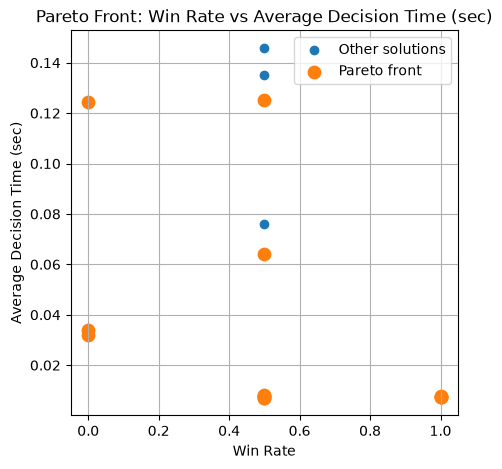

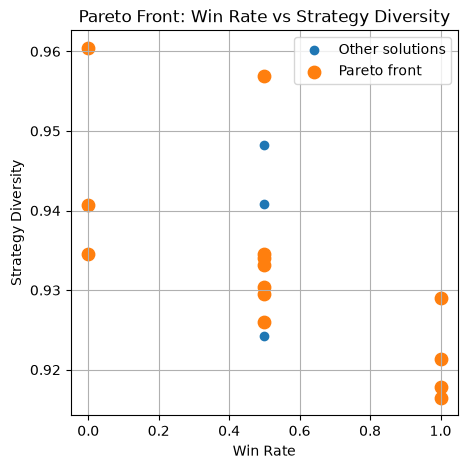

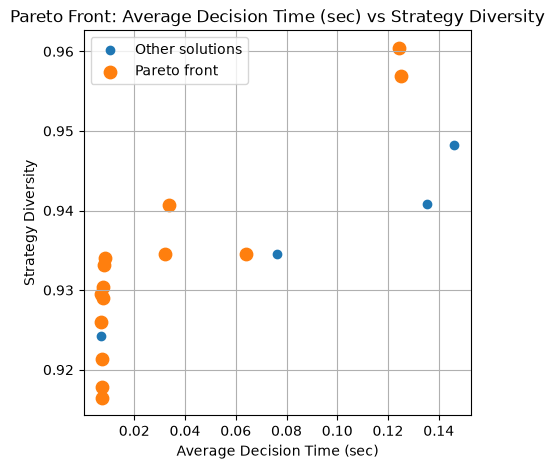

In [76]:
import matplotlib.pyplot as plt

other_indices = [i for i in range(len(results_df)) if i not in pareto_indices]
pairs = [("win_rate", "avg_decision_time", "Win Rate", "Average Decision Time (sec)"), ("win_rate", "strategy_diversity", "Win Rate", "Strategy Diversity"), ("avg_decision_time", "strategy_diversity", "Average Decision Time (sec)", "Strategy Diversity")]
for x_col, y_col, x_label, y_label in pairs:
    plt.figure(figsize=(5, 5))
    plt.scatter(results_df.iloc[other_indices][x_col], results_df.iloc[other_indices][y_col], label="Other solutions")
    plt.scatter(results_df.iloc[pareto_indices][x_col], results_df.iloc[pareto_indices][y_col], label="Pareto front", s=80)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(f"Pareto Front: {x_label} vs {y_label}")
    plt.legend()
    plt.grid()
    plt.show()

Для демонстрации итоговой конфигурации игрового ИИ была выбрана одна из недоминируемых особей первого фронта Парето.

* веса эвристической функции: `(1.4011, 4.473762, 4.65273)`;
* глубина поиска Minimax: `2`, у которой Win Rate = `1.0`, среднее время принятия решения `0.007754` секунды и Strategy Diversity = `0.929036`

Сравним эту конфигурацию с **baseline**, которую рассматривали в качестве базовой:
* weight = `(2, 3, 4)`
* depth = `4`

In [73]:
baseline_metrics = evaluate_individual(weights=(2.0, 3.0, 4.0), depth=4, n_games=100)
evolved_metrics = evaluate_individual(weights=(1.4011, 4.473762, 4.65273), depth=2, n_games=100)
comparison_df = pd.DataFrame([{"Model": "Baseline", "Weights": (2.0, 3.0, 4.0), "Depth": 4, **baseline_metrics},
    {"Model": "NSGA-II", "Weights": (1.4011, 4.473762, 4.65273), "Depth": 2, **evolved_metrics}])

comparison_df

,Model,Weights,Depth,win_rate,draw_rate,loss_rate,avg_decision_time,strategy_diversity
0,Baseline,"(2.0, 3.0, 4.0)",4,0.5,0.0,0.5,0.142154,0.940808
1,NSGA-II,"(1.4011, 4.473762, 4.65273)",2,1.0,0.0,0.0,0.007889,0.929036


Мы получили следующие **результаты**:
| Критерий  | Baseline | NSGA-II | Результат          |
|----------|----|--------|--------------------|
| Win Rate | 0.5 | 1.0 | Улучшение в 2 раза |
| Decision Time | 0.142154 | 0.007889 | Улучшение в 18 раз |
| Strategy Diversity | 0.940808 | 0.929036 | Ухудшение на 1.25% |

Таким образом, эволюционная оптимизация позволила не только повысить качество игры, но и существенно сократить вычислительные затраты. Небольшое снижение разнообразия стратегии стало _компромиссом_, сопровождающим улучшение двух других критериев

Полученные результаты демонстрируют **практическую пользу** многокритериальной оптимизации: алгоритм `NSGA-II` позволил найти конфигурацию, которая превосходит исходную модель по двум основным показателям — качеству игры и скорости принятия решений

Да, мы выбрали по нашему мнению лучшую модель, но давайте зафиксируем **3 наилучших**, исходя из полученных данных, ведь в каждом наборе есть свои плюсы и минусы по критериям:
1. **высоконадежное** и быстрое решение: `weights = (1.4011, 4.473762, 4.65273), depth = 2`
| Критерий  | Значение |
|----------|----|
| Win Rate | 1.0 |
| Average decision time | 0.007754 |
| Strategy diversity | 0.929036 |
2. самое **быстрое** решение: `weights = (3.596356, 3.041131, 2.437693), depth = 2`
| Критерий  | Значение |
|----------|----|
| Win Rate | 0.5 |
| Average decision time | 0.006989 |
| Strategy diversity | 0.926046 |
3. решение с **максимальным разнообразием** стратегии: `weights = (2.521914, 0.598616, 2.601012), depth = 4`
| Критерий  | Значение |
|----------|----|
| Win Rate | 0.0 |
| Average decision time | 0.124446 |
| Strategy diversity | 0.960427 |

Хочется сравнить сам алгоритм **NSGA-II** с методом взвешенной суммы. Вспомним суть **Weighted Sum**, которая объединяет три критерия в одну оценку с помощью весов:

$S(x)=w_1 f_1(x)+w_2 f_2(x)+w_3 f_3(x)$, где:
* $f_1$ — качество игры (win_rate);
* $f_2$ — скорость (avg_decision_time);
* $f_3$ — разнообразие стратегии (strategy_diversity);
* $w_1, w_2, w_3$ — важность критериев

Но есть две особенности:
1. Нужно заранее выбрать веса, то есть определить приоритеты
2. Метод обычно выбирает одно лучшее решение для конкретного набора весов, а не целый фронт компромиссов

Нам необходимо **нормировать**:
1. максимизируем критерии: $f_{\text{norm}}(x)=\frac{x-x_{\min}}{x_{\max}-x_{\min}}$
2. минимизируем критерии: $t_{\text{norm}}(x)=\frac{x_{\max}-x}{x_{\max}-x_{\min}}$

Обрати внимание: после преобразования для всех трёх критериев большее значение означает лучший результат

Перепишем некоторые функции, чтобы мы могли собрать генетический алгоритм на **взвешенной сумме**, а именно подсчет функции, бинарный турнир на выбор родителей и создание детей, а потом все соберем в _единую_ функцию

In [83]:
def calculate_weighted_scores(results_df, criterion_weights):
    w1, w2, w3 = criterion_weights
    win_min = results_df["win_rate"].min()
    win_max = results_df["win_rate"].max()
    time_min = results_df["avg_decision_time"].min()
    time_max = results_df["avg_decision_time"].max()
    div_min = results_df["strategy_diversity"].min()
    div_max = results_df["strategy_diversity"].max()
    win_norm = (results_df["win_rate"] - win_min) / (win_max - win_min) if win_max != win_min else 0.5
    time_norm = (time_max - results_df["avg_decision_time"]) / (time_max - time_min) if time_max != time_min else 0.5
    diversity_norm = (results_df["strategy_diversity"] - div_min) / (div_max - div_min) if div_max != div_min else 0.5
    return w1 * win_norm + w2 * time_norm + w3 * diversity_norm

def weighted_tournament(population, scores):
    i, j = random.sample(range(len(population)), 2)
    if scores[i] > scores[j]:
        return population[i]
    if scores[j] > scores[i]:
        return population[j]
    return random.choice([population[i], population[j]])

def create_weighted_offspring(population, scores, offspring_size):
    offspring = []
    while len(offspring) < offspring_size:
        parent1 = weighted_tournament(population, scores)
        parent2 = weighted_tournament(population, scores)
        child = crossover(parent1, parent2)
        child = mutate(child)
        offspring.append(child)
    return offspring

```mermaid
flowchart TD
    A([Начало]) --> B[Задание весов критериев]
    B --> C[Создание начальной популяции]
    C --> D[Оценка особей:<br/>Win rate, Decision time, Diversity]
    D --> E{Достигнуто максимальное<br/>число поколений?}
    E -- Нет --> F[Нормализация критериев]
    F --> G[Расчёт взвешенной оценки<br/>Weighted Score]
    G --> H[Выбор родителей<br/>бинарным турниром]
    H --> I[Скрещивание]
    I --> J[Мутация]
    J --> K[Оценка потомков]
    K --> L[Объединение родителей<br/>и потомков]
    L --> M[Нормализация критериев<br/>и расчёт Weighted Score]
    M --> N[Отбор особей<br/>с наибольшей оценкой]
    N --> O[Формирование нового поколения]
    O --> E
    E -- Да --> P[Выбор решения<br/>с максимальной оценкой]
    P --> Q([Конец])
```


In [85]:
def run_weighted_sum_ga(population_size=20, generations=10, n_games=20, criterion_weights=(0.33, 0.33, 0.34)):
    population = create_population(population_size)
    results_df = evaluate_population(population, n_games)
    history = []
    for generation in range(generations):
        print(f"\nПоколение {generation + 1}")
        scores = calculate_weighted_scores(results_df, criterion_weights)
        offspring = create_weighted_offspring(population, scores, population_size)
        combined_population = population + offspring
        combined_results = evaluate_population(combined_population, n_games)
        combined_scores = calculate_weighted_scores(combined_results, criterion_weights)
        selected_indices = combined_scores.sort_values(ascending=False).index[:population_size].tolist()
        population = [combined_population[i].copy() for i in selected_indices]
        results_df = combined_results.iloc[selected_indices].reset_index(drop=True)
        history.append(results_df.copy())
        print("Лучшая взвешенная оценка:", combined_scores.iloc[selected_indices].max())
        print("Размер популяции:", len(population))
    return population, results_df, history

Ну и запустим этот алгоритм для **взвешенной суммы**, чтобы проверить все

In [86]:
weighted_population, weighted_results, weighted_history = (run_weighted_sum_ga(population_size=20, generations=10, n_games=20, criterion_weights=(0.33, 0.33, 0.34)))


Поколение 1
Лучшая взвешенная оценка: 0.7948608240856764
Размер популяции: 20

Поколение 2
Лучшая взвешенная оценка: 0.7202576118114841
Размер популяции: 20

Поколение 3
Лучшая взвешенная оценка: 0.7232656045176447
Размер популяции: 20

Поколение 4
Лучшая взвешенная оценка: 0.7426468374354848
Размер популяции: 20

Поколение 5
Лучшая взвешенная оценка: 0.8753244613185149
Размер популяции: 20

Поколение 6
Лучшая взвешенная оценка: 0.8447624426684621
Размер популяции: 20

Поколение 7
Лучшая взвешенная оценка: 0.9336429034867753
Размер популяции: 20

Поколение 8
Лучшая взвешенная оценка: 0.922615886578347
Размер популяции: 20

Поколение 9
Лучшая взвешенная оценка: 0.9991618716018109
Размер популяции: 20

Поколение 10
Лучшая взвешенная оценка: 0.9640990549798377
Размер популяции: 20


Найдем **лучшее** решение для взвешенной функции, чтобы впоследствие сравнить его с NSGA-II

In [89]:
final_scores = calculate_weighted_scores(weighted_results, criterion_weights=(0.33, 0.33, 0.34))
weighted_results = weighted_results.copy()
weighted_results["weighted_score"] = final_scores
best_weighted = weighted_results.loc[weighted_results["weighted_score"].idxmax()]
print("Лучшее решение Weighted Sum:")
print("Weights:", best_weighted["weights"])
print("Depth:", best_weighted["depth"])
print("Win rate:", best_weighted["win_rate"])
print("Decision time:", best_weighted["avg_decision_time"])
print("Diversity:", best_weighted["strategy_diversity"])
print("Weighted score:", best_weighted["weighted_score"])

Лучшее решение Weighted Sum:
Weights: (2.775819635541425, 2.054879476475145, 2.220858835998968)
Depth: 2
Win rate: 1.0
Decision time: 0.007445289985189447
Diversity: 0.9213254464582534
Weighted score: 0.665


Сравним полученные **результаты**:
| Алгоритм  | Win rate | Время, сек | Diversity |
|----------|----|----|----|
| Weighted Sum | 1.0 | 0.007445 | 0.921325 |
| NSGA-II: быстрое решение | 0.5 | 0.006989 | 0.926046 |
| NSGA-II: максимальная победа среди выбранных решений | 1.0 | 0.007754 | 0.929036 |
| NSGA-II: максимальное разнообразие | 0.0 | 0.124446 | 0.960427 |

NSGA-II оптимизирует три критерия одновременно и формирует множество недоминируемых решений, позволяя выбирать между качеством игры, скоростью принятия решений и разнообразием стратегии. Weighted Sum объединяет все критерии в одну взвешенную оценку. В результате алгоритм нашёл решение с долей побед 1.0, временем принятия решения 0.007445 секунды и разнообразием стратегии 0.921325. NSGA-II также нашёл решение с долей побед 1.0, но с несколько большим временем принятия решения (0.007754 секунды) и более высоким разнообразием (0.929036). Кроме того, он сохранил альтернативные решения с другими сочетаниями критериев.

**Вывод**: Weighted Sum позволяет найти решение с учётом заранее заданных приоритетов, однако результат зависит от выбранных весов. NSGA-II оказался более гибким для данной задачи, поскольку сохраняет множество компромиссных решений и не требует заранее определять относительную важность критериев.